# 미들웨어와 6개 훅

**이 노트북에서 할 일**

1. 훅 여섯 개를 함수로 하나씩 만들고, 실행될 때마다 이름을 목록에 적습니다.
2. 도구가 필요한 질문으로 에이전트를 실행해 훅이 실행된 순서를 읽습니다.
3. 도구를 쓰지 말라고 적은 인사 질문으로 실행하고 훅 실행 횟수를 비교합니다.

**준비물** — `.env` 파일의 `OPENAI_API_KEY`, 데이터 파일은 없습니다. 모델 호출은 3번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

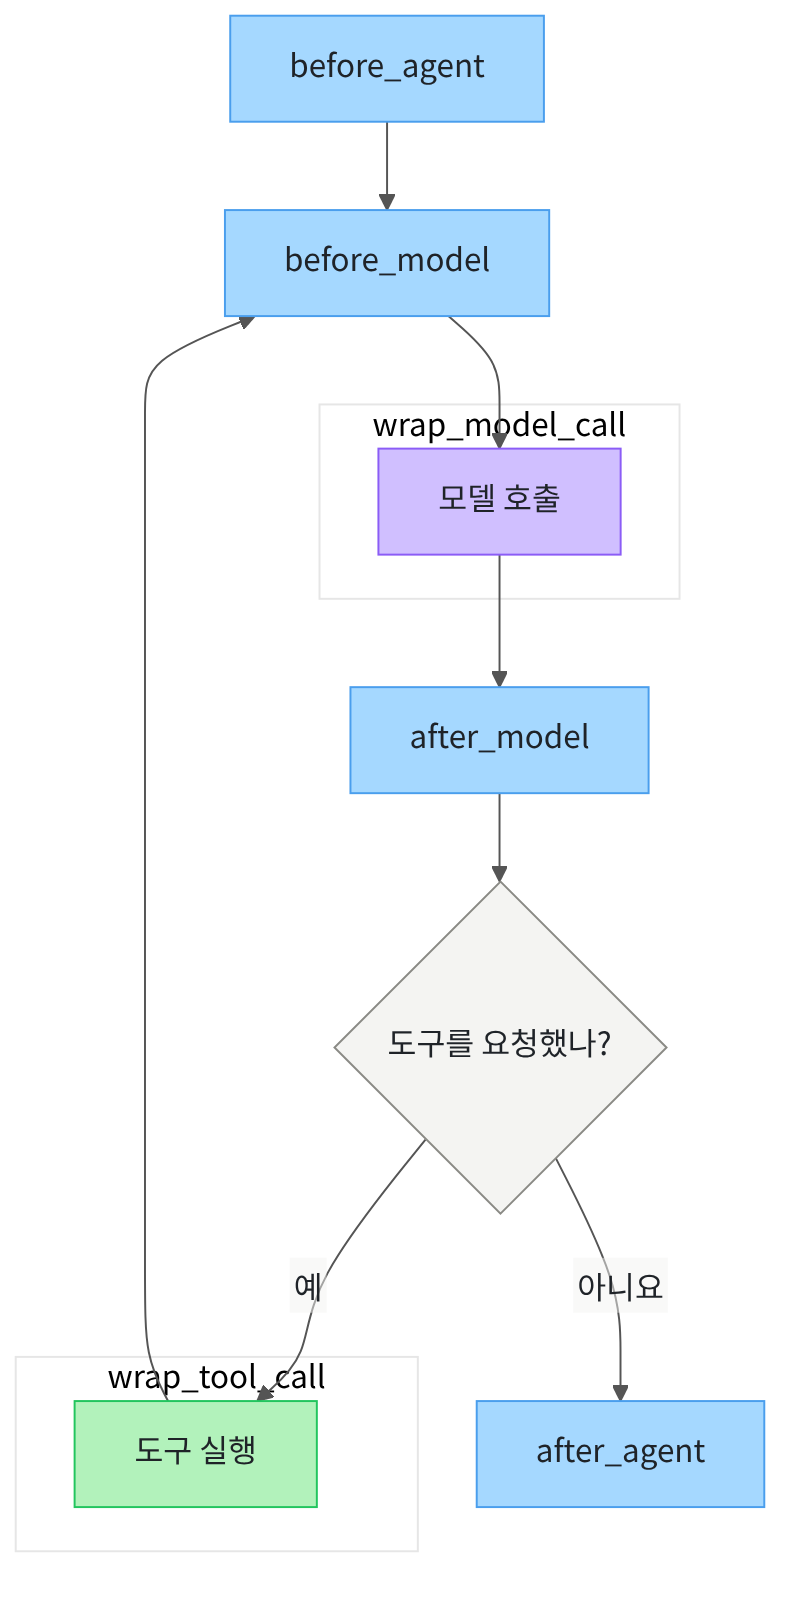

위에서 아래로 읽습니다. 파란 상자가 이번에 만들 훅입니다. 보라 상자는 모델, 초록 상자는 도구입니다.
모델이 도구를 요청하면 도구 상자를 거쳐 다시 모델 호출로 돌아갑니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 한 번에 불러옵니다. 훅을 만드는 데코레이터 여섯 개가 여기에 들어 있습니다.
함께 불러오는 `Callable`, `AgentState`, `Runtime`은 타입 힌트에 쓰는 이름입니다.
타입 힌트는 함수가 받는 값의 종류를 적어 두는 표시입니다. 이 절의 훅 함수에 붙인 타입 힌트는 실행 결과를 바꾸지 않습니다.

In [2]:
# 에이전트·훅·모델·도구를 만드는 도구를 불러옵니다
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import AgentState, Runtime
from langchain.agents.middleware import ModelRequest, ModelResponse, ToolCallRequest
from langchain.agents.middleware import after_agent, after_model, before_agent, before_model
from langchain.agents.middleware import wrap_model_call, wrap_tool_call
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import ToolMessage

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


## 2. 모델과 도구 만들기

`init_chat_model()` 함수는 모델 이름을 받아 모델 객체를 만듭니다.
temperature 값은 답을 고를 때의 무작위 정도입니다. 0으로 두면 매번 비슷한 답을 고릅니다.
추론 설정(`reasoning_effort="none"`)은 모델이 긴 추론 없이 바로 답하게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름에 `gpt-5.4-mini`, temperature에 `0.0`이 보이면 준비가 끝났습니다.
temperature 값을 0으로 두어도 답 문장이 매번 똑같다고 보장하지는 않습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

에이전트가 쓸 도구를 하나 만듭니다. 도구는 모델이 필요할 때 부르는 보통의 파이썬 함수입니다.
함수 위의 `@tool` 줄은 아래 함수를 에이전트용 도구로 등록합니다.
큰따옴표 세 개로 쓴 설명문은 모델이 도구를 고를 때 읽는 안내입니다.

In [5]:
# 자료실 운영 시간을 알려 주는 도구를 만듭니다
@tool
def lookup_hours(day: str) -> str:
    """자료실 운영 시간을 조회합니다. day에는 "평일" 또는 "토요일"을 넣습니다."""
    if day == "평일":
        return "평일 09:00~20:00"
    return "토요일 10:00~17:00"


print("도구 이름:", lookup_hours.name)

도구 이름: lookup_hours


**결과 읽기** — 도구 이름이 `lookup_hours`로 나옵니다. 모델도 이 이름으로 도구를 부릅니다.

## 3. 훅 여섯 개 만들기

훅은 에이전트가 정해진 순간에 알아서 실행하는 함수입니다. 우리가 직접 부르지 않습니다.
각 훅은 실행될 때 자기 이름을 `trace` 목록에 적습니다. 먼저 빈 목록을 만듭니다.

In [6]:
# 훅이 실행된 순서를 적을 빈 목록을 만듭니다
trace = []
print("기록 개수:", len(trace))

기록 개수: 0


**결과 읽기** — 아직 아무 훅도 실행되지 않았으므로 기록 개수는 `0`입니다.

첫 번째 훅은 에이전트 실행이 시작될 때 한 번 실행됩니다.
`@before_agent` 줄은 아래 함수를 "시작할 때 실행할 훅"으로 등록합니다.
state 값은 지금까지의 대화 기록이고, runtime 값은 실행 환경 정보입니다. 이번에는 둘 다 쓰지 않습니다.

In [7]:
# 에이전트 실행이 시작될 때 한 번 실행되는 훅
@before_agent
def record_before_agent(state: AgentState, runtime: Runtime) -> None:
    trace.append("before_agent")

출력은 없습니다. 함수를 만들기만 했고 아직 실행하지 않았기 때문입니다.

두 번째 훅은 모델을 부르기 직전마다 실행됩니다. 모델을 두 번 부르면 두 번 실행됩니다.

In [8]:
# 모델을 부르기 직전마다 실행되는 훅
@before_model
def record_before_model(state: AgentState, runtime: Runtime) -> None:
    trace.append("before_model")

세 번째 훅은 모델 호출을 앞뒤로 감쌉니다. 이런 훅을 감싸기형 훅이라고 부릅니다.
`handler` 함수는 실제로 모델을 부릅니다. `handler(request)` 줄에서 모델이 실행됩니다.
그래서 이 줄 앞에 적은 기록은 모델 호출 전에, 뒤에 적은 기록은 호출 후에 남습니다.

In [9]:
# 모델 호출을 앞뒤로 감싸는 훅
@wrap_model_call
def record_wrap_model(request: ModelRequest, handler: Callable) -> ModelResponse:
    trace.append("wrap_model_call 시작")
    response = handler(request)  # 여기서 실제 모델이 실행됩니다
    trace.append("wrap_model_call 끝")
    return response

네 번째 훅은 모델 응답을 받은 직후마다 실행됩니다.

In [10]:
# 모델 응답을 받은 직후마다 실행되는 훅
@after_model
def record_after_model(state: AgentState, runtime: Runtime) -> None:
    trace.append("after_model")

다섯 번째 훅은 도구 호출을 앞뒤로 감쌉니다. 모양은 세 번째 훅과 같습니다.
여기서 `handler(request)`는 모델이 아니라 도구를 실행합니다.

In [11]:
# 도구 호출을 앞뒤로 감싸는 훅
@wrap_tool_call
def record_wrap_tool(request: ToolCallRequest, handler: Callable) -> ToolMessage:
    trace.append("wrap_tool_call 시작")
    result = handler(request)  # 여기서 실제 도구가 실행됩니다
    trace.append("wrap_tool_call 끝")
    return result

마지막 훅은 에이전트 실행이 끝날 때 한 번 실행됩니다.

In [12]:
# 에이전트 실행이 끝날 때 한 번 실행되는 훅
@after_agent
def record_after_agent(state: AgentState, runtime: Runtime) -> None:
    trace.append("after_agent")

## 4. 에이전트에 훅 등록하고 실행하기

`create_agent()` 함수의 `middleware` 인자에 훅 목록을 넘깁니다. 목록 순서는 07절에서 따로 다룹니다.

In [13]:
# 도구 1개와 훅 6개를 등록해 에이전트를 만듭니다
hooks = [
    record_before_agent,
    record_before_model,
    record_wrap_model,
    record_after_model,
    record_wrap_tool,
    record_after_agent,
]
agent = create_agent(model, tools=[lookup_hours], middleware=hooks)
print("등록한 훅 수:", len(hooks))

등록한 훅 수: 6


**결과 읽기** — 등록한 훅 수가 `6`입니다.

이제 운영 시간을 묻습니다. 답하려면 도구가 필요한 질문입니다.

In [14]:
# 도구가 필요한 질문으로 에이전트를 한 번 실행합니다
question = {"messages": [{"role": "user", "content": "자료실 평일 운영 시간을 알려 주세요."}]}
result = agent.invoke(question)
last_message = result["messages"][-1]
print("최종 답:", last_message.text)

최종 답: 자료실 평일 운영 시간은 **09:00~20:00**입니다.


**결과 읽기** — 최종 답에 `09:00~20:00`이 들어 있으면 모델이 도구 결과를 읽고 답한 것입니다.
답 문장은 실행할 때마다 조금씩 달라질 수 있습니다.

훅이 남긴 기록을 번호와 함께 출력합니다.
반복문에 쓴 `enumerate(trace, start=1)` 함수는 목록의 값마다 1부터 시작하는 번호를 붙여 줍니다.

In [15]:
# 훅이 실행된 순서를 번호와 함께 출력합니다
for number, name in enumerate(trace, start=1):
    print(number, name)

1 before_agent
2 before_model
3 wrap_model_call 시작
4 wrap_model_call 끝
5 after_model
6 wrap_tool_call 시작
7 wrap_tool_call 끝
8 before_model
9 wrap_model_call 시작
10 wrap_model_call 끝
11 after_model
12 after_agent


**결과 읽기** — 1번은 `before_agent`, 마지막은 `after_agent`입니다.
그 사이에서 `before_model`부터 `after_model`까지 모델 호출 한 묶음이 두 번 나옵니다.
두 묶음 사이에 `wrap_tool_call 시작`과 `wrap_tool_call 끝`이 끼어 있습니다.

대화 기록에 어떤 메시지가 쌓였는지도 봅니다. 메시지 종류 중 human은 사용자, ai는 모델, tool은 도구가 만든 메시지입니다.

In [16]:
# 대화 기록에 쌓인 메시지를 종류별로 출력합니다
for message in result["messages"]:
    print(message.type, "|", message.text)

human | 자료실 평일 운영 시간을 알려 주세요.
ai | 
tool | 평일 09:00~20:00
ai | 자료실 평일 운영 시간은 **09:00~20:00**입니다.


**결과 읽기** — 두 번째 줄의 ai 메시지는 글자가 비어 있습니다. 이 메시지는 답 대신 도구를 요청했습니다.
그다음 tool 메시지에 `평일 09:00~20:00`이 있고, 마지막 ai 메시지가 최종 답입니다.
ai 메시지 하나가 모델 호출 한 번입니다. 이제 ai 메시지 수와 훅 기록 수를 따로 세어 비교합니다.

In [17]:
# ai 메시지 수(모델 호출 횟수)와 훅 기록 수를 따로 셉니다
ai_messages = 0
for message in result["messages"]:
    if message.type == "ai":
        ai_messages = ai_messages + 1
model_calls = trace.count("before_model")
tool_calls = trace.count("wrap_tool_call 시작")
print("ai 메시지 수(모델 호출 횟수):", ai_messages)
print("before_model 기록 수:", model_calls)
print("도구 호출 횟수:", tool_calls)

ai 메시지 수(모델 호출 횟수): 2
before_model 기록 수: 2
도구 호출 횟수: 1


**결과 읽기** — ai 메시지 수 `2`, before_model 기록 수 `2`, 도구 호출 횟수 `1`입니다.
모델을 2번 불렀고, before_model 훅도 호출마다 한 번씩 실행됐습니다.

모델 답 문장과 상관없이 늘 성립해야 하는 관계를 `assert` 줄로 확인합니다. 관계가 틀리면 오류가 납니다.

In [18]:
# 매번 같아야 하는 관계 다섯 가지를 확인합니다
assert trace[0] == "before_agent"
assert trace[-1] == "after_agent"
assert model_calls == ai_messages
assert trace.count("wrap_model_call 시작") == ai_messages
assert trace.count("after_model") == ai_messages
print("다섯 관계가 모두 맞습니다")

다섯 관계가 모두 맞습니다


**결과 읽기** — `다섯 관계가 모두 맞습니다`가 출력됐습니다. 모델 훅 세 개 모두 모델 호출 횟수만큼 실행됐습니다.

## 5. 질문 하나 바꿔 보기

도구를 쓰지 말라고 적은 인사 질문으로 바꿉니다. 실행 전에 예상해 봅니다.
모델이 도구를 부르지 않으면 모델 호출은 한 번이고, 도구 훅은 실행되지 않을 것입니다.

In [19]:
# 기록을 비우고, 도구를 쓰지 말라고 적은 질문으로 다시 실행합니다
trace.clear()
greeting = {"messages": [{"role": "user", "content": "도구를 쓰지 말고 한 문장으로 인사해 주세요."}]}
greeting_result = agent.invoke(greeting)
print("최종 답:", greeting_result["messages"][-1].text)
for number, name in enumerate(trace, start=1):
    print(number, name)

최종 답: 안녕하세요, 무엇을 도와드릴까요?
1 before_agent
2 before_model
3 wrap_model_call 시작
4 wrap_model_call 끝
5 after_model
6 after_agent


**결과 읽기** — 기록이 `before_agent`로 시작해 `after_agent`로 끝나는 것은 앞과 같습니다.
이번에는 `wrap_tool_call 시작`이 없고 모델 호출 묶음이 한 번뿐입니다. 인사 문장은 실행할 때마다 달라질 수 있습니다.

In [20]:
# 두 질문의 호출 횟수를 비교합니다
print("인사 질문 모델 호출 횟수:", trace.count("before_model"))
print("인사 질문 도구 호출 횟수:", trace.count("wrap_tool_call 시작"))
print("운영 시간 질문 모델 호출 횟수:", model_calls)
print("운영 시간 질문 도구 호출 횟수:", tool_calls)

인사 질문 모델 호출 횟수: 1
인사 질문 도구 호출 횟수: 0
운영 시간 질문 모델 호출 횟수: 2
운영 시간 질문 도구 호출 횟수: 1


**결과 읽기** — 인사 질문은 모델 `1`번, 도구 `0`번입니다. 운영 시간 질문은 모델 2번, 도구 1번이었습니다.
훅이 실행되는 횟수는 등록한 개수가 아니라, 에이전트가 실제로 모델과 도구를 몇 번 불렀는지에 따라 정해집니다.

## 정리

- `before_agent`와 `after_agent`는 에이전트를 한 번 실행할 때 한 번씩 실행됩니다.
- 모델 훅 세 개는 모델을 부를 때마다, `wrap_tool_call`은 도구를 부를 때마다 실행됩니다.
- 감싸기형 훅은 `handler(request)` 줄을 기준으로 호출 전과 호출 후가 나뉩니다.

다음 절에서는 이 훅 자리에 개인정보를 가리는 기능을 넣습니다.